# What survives encoding?
A chart can reconstruct a signal even when an untrained posterior sample cannot. We compare chart projection, the actual `ESDM.encode` posterior mean, and one sampled latent across ranks. A separate, short, end-to-end fit tests whether the rank-eight posterior mean retains more information after training on these synthetic signals.

From the repository root: `uv run --no-sync python notebooks/run.py`. This runs both notebooks, embeds the figures and collects `docs/paper/v2-results/experiment.json`. No data downloads or checkpoints.

In [1]:
from pathlib import Path
import sys
root = Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()
sys.path.insert(0, str(root))
import matplotlib.pyplot as plt
import torch
from IPython.display import display
from esdm.experiments.v2_readout import path_data, protocol, encoding_experiment, trained_encoder_diagnostic
torch.set_num_threads(1)
data = path_data()
settings = protocol(data)
print(f"Seed {settings['seed']} | CPU | {settings['n_train']} train / {settings['n_test']} held out | {settings['features']} features")

Seed 3407 | CPU | 512 train / 512 held out | 32 features


### Signals and probes
We draw independent Gaussian coefficients on an unweighted 32-node path. Mode $k$ has variance $1/(1+(k/4)^2)$ for $k=0,\ldots,31$. All ranks see the same 512 clean training and 512 clean held-out cases. Lower-frequency modes have more energy by construction; a favourable result for the path chart is expected.

For rank $q$, the chart estimate is $(xU_q)U_q^\top$. For the encoder, instantiate a fresh seed-3407 ESDM per rank; run `mu, logvar, z = model.encode(x)`; fit an affine least-squares probe from each **training** representation (mean or one sample) to clean features. No ESDM parameters are fitted in this rank sweep. Evaluate the fixed probes on held-out codes. This probes decodable information, not the model’s own decoder: the wave path in `ESDM.forward` receives features directly.

MSE is in squared original feature units: average over 32 features per case, then across held-out cases. The paired uncertainty below resamples cases jointly, not model initialisations.

In [2]:
encoding = encoding_experiment(data)
print('Rank     Chart MSE     Mean-probe MSE   Sample-probe MSE   95% CI: sample minus mean')
for row in encoding['rows']:
    lo, hi = row['sample_minus_mu']['ci95']
    print(f"{row['rank']:>4}    {row['chart_mse']:>10.4g}        {row['mu_probe_mse']:>10.4g}         {row['sample_probe_mse']:>10.4g}   [{lo:.5f}, {hi:.5f}]")

Rank     Chart MSE     Mean-probe MSE   Sample-probe MSE   95% CI: sample minus mean
   2        0.1369            0.1564             0.1925   [0.03238, 0.03982]
   4       0.09269            0.1353             0.1936   [0.05399, 0.06314]
   8       0.04536           0.08821             0.1912   [0.09777, 0.10856]
  16       0.01563           0.04326             0.1905   [0.14057, 0.15412]
  32     1.469e-30         1.026e-13              0.181   [0.17492, 0.18745]


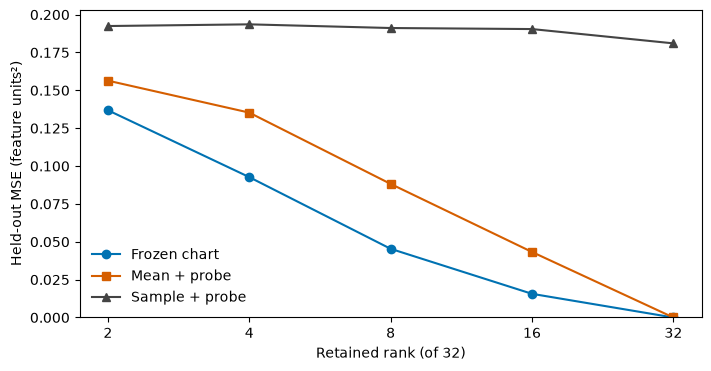

In [3]:
rows = encoding['rows']
ranks = [r['rank'] for r in rows]
fig, ax = plt.subplots(figsize=(7, 3.6), layout='constrained')
for key, label, marker, colour in [('chart_mse','Frozen chart','o','#0072B2'), ('mu_probe_mse','Mean + probe','s','#D55E00'), ('sample_probe_mse','Sample + probe','^','#444444')]:
    ax.plot(ranks, [r[key] for r in rows], marker=marker, color=colour, label=label)
ax.set(xscale='log', xlabel='Retained rank (of 32)', ylabel='Held-out MSE (feature units²)', ylim=(0, None))
ax.set_xticks(ranks, labels=ranks); ax.minorticks_off(); ax.legend(frameon=False)
plt.show()

At rank eight, chart reconstruction has MSE 0.0454, compared with 0.0882 from the encoder mean and 0.1912 from one posterior draw. Increasing rank improves the chart and the mean probe substantially; the sampled-code probe improves little, and not monotonically. At full rank the mean probe reverses the untrained affine map to numerical precision, whereas the sampled-code MSE is still 0.1810. The chart and probes use float64 arithmetic; encoder outputs are computed in float32. These comparisons characterise this smooth synthetic population, one untrained encoder per rank, and one posterior draw per case. They do not estimate semantic fidelity on real embeddings.

### One full-model training run at rank eight
A fresh seed-3407 ESDM receives the same clean training signals as both inputs and targets. In training mode, each update computes `model(batch).loss` (the implemented ELBO loss), backpropagates and steps Adam over the full model. Two seeded permutations of the 512 training cases give 32 minibatches of 32; we use the repository defaults for learning rate (0.0003) and weight decay (0.00001), with no gradient clipping or tuning. Stop and report the first nonfinite loss, gradient or parameter rather than retrying.

Before and after the fit, use `ESDM.encode` on clean cases and refit a separate affine probe using only the 512 training means. Compare probe errors on the same 512 held-out cases. Evaluation does not advance the clock or the training random stream. The interval resamples held-out cases, not fits. A lower training loss on different minibatches would not establish improved held-out encoding; the reconstruction path receives raw features directly.

In [4]:
fit = trained_encoder_diagnostic(data)
print(f"Stop: {fit['stop_reason']}; {fit['completed_updates']}/{fit['planned_updates']} updates; {fit['finite_gradient_steps']} finite gradient checks.")
trace = fit['step_trace']
print(f"First and last minibatch losses (different inputs, pre-update): {trace[0]['loss']}, {trace[-1]['loss']}")
if fit['nonfinite_step'] is not None:
    print('First nonfinite step:', fit['nonfinite_step'], '— no retry or post-fit probe.')
else:
    d = fit['after_minus_before']; lo, hi = d['ci95']
    print(f"Held-out mean-probe MSE: {fit['before_mu_probe_mse']:.8f} -> {fit['after_mu_probe_mse']:.8f}")
    print(f"After − before: {d['mean']:+.3e}; paired 95% interval [{lo:+.3e}, {hi:+.3e}]. Negative favours the trained encoder.")
    print(f"Global gradient L2 range: {min(s['grad_l2'] for s in trace):.4g} to {max(s['grad_l2'] for s in trace):.4g}")
    print(f"Readout gains: {fit['before_gain_range']} -> {fit['after_gain_range']}; largest absolute logit change: {fit['max_abs_logit_change']:.6g}")
    if hi < 0: print('Less held-out probe error after this single fixed synthetic fit.')
    elif lo > 0: print('More held-out probe error after this single fixed synthetic fit.')
    else: print('No resolved change in held-out probe error on this split.')

Stop: fixed_budget; 32/32 updates; 32 finite gradient checks.
First and last minibatch losses (different inputs, pre-update): 15.03338623046875, 15.613920211791992
Held-out mean-probe MSE: 0.08821115 -> 0.09270693
After − before: +4.496e-03; paired 95% interval [+3.985e-03, +5.029e-03]. Negative favours the trained encoder.
Global gradient L2 range: 3.398 to 4.293
Readout gains: [0.9776009917259216, 0.9938691258430481] -> [0.977843165397644, 0.9940529465675354]; largest absolute logit change: 0.0106643
More held-out probe error after this single fixed synthetic fit.


In [5]:
display({'application/json': {'protocol': settings, 'encoding': encoding, 'trained_encoder': fit}, 'text/plain': 'Machine-readable encoding and full-model training results.'}, raw=True)

Machine-readable encoding and full-model training results.